In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from sqlalchemy import create_engine, event, text
from sqlalchemy.engine import URL

ROOT = r'D:\Bluestock work\bluestock-fintech-analysis1'
RAW_DIR = os.path.join(ROOT, 'data', 'raw')
PROCESSED_DIR = os.path.join(ROOT, 'data', 'processed')
REPORTS_DIR = os.path.join(ROOT, 'reports')
DB_PATH = os.path.join(PROCESSED_DIR, 'bluestock_dw.db')

TRADING_DAYS = 252
RF_ANNUAL = 0.065
RF_DAILY = RF_ANNUAL / TRADING_DAYS

engine = create_engine(URL.create('sqlite', database=DB_PATH))

@event.listens_for(engine, 'connect')
def turn_on_foreign_keys(dbapi_connection, connection_record):
    cursor = dbapi_connection.cursor()
    cursor.execute('PRAGMA foreign_keys = ON')
    cursor.close()

In [2]:
bench_path = glob.glob(os.path.join(RAW_DIR, '*10_benchmark_indices*'))[0]
bench = pd.read_csv(bench_path)

print(bench.shape)
print(bench.dtypes)
print(bench['date'].head())
print(bench['index_name'].value_counts())

(8050, 3)
date               str
index_name         str
close_value    float64
dtype: object
0    2022-01-03
1    2022-01-04
2    2022-01-05
3    2022-01-06
4    2022-01-07
Name: date, dtype: str
index_name
NIFTY50            1150
NIFTY100           1150
NIFTY_MIDCAP150    1150
BSE_SMALLCAP       1150
NIFTY500           1150
CRISIL_LIQUID      1150
CRISIL_GILT        1150
Name: count, dtype: int64


In [3]:
NIFTY_NAME = 'Nifty 100'
DATE_FORMAT = '%Y-%m-%d'

idx = bench[bench['index_name'] == NIFTY_NAME].copy()
print('Rows for', NIFTY_NAME, ':', len(idx))

idx['date'] = pd.to_datetime(idx['date'], format=DATE_FORMAT, errors='coerce')
idx['close_value'] = pd.to_numeric(idx['close_value'], errors='coerce')

print('Dates not readable:', idx['date'].isnull().sum())
print('Close not a number:', idx['close_value'].isnull().sum())
print('Close zero or below:', (idx['close_value'] <= 0).sum())
print('Repeated dates:', idx.duplicated(subset=['date']).sum())

idx = idx.dropna(subset=['date', 'close_value'])
idx = idx[idx['close_value'] > 0]
idx = idx.drop_duplicates(subset=['date'], keep='last').sort_values('date')

print(idx['date'].min().date(), 'to', idx['date'].max().date(), '| rows:', len(idx))

Rows for Nifty 100 : 0
Dates not readable: 0
Close not a number: 0
Close zero or below: 0
Repeated dates: 0
NaT to NaT | rows: 0


In [ ]:
idx['date'] = pd.to_datetime(idx['date'])

idx_close = idx.set_index('date')['close_value']
idx_daily = idx_close.resample('D').last().ffill(limit=7)

idx_daily.index = pd.to_datetime(idx_daily.index)


print('Index days:', len(idx_close), '| calendar days:', len(idx_daily))
print('Calendar days still empty:', idx_daily.isnull().sum())

<class 'pandas.api.typing.NaTType'>
Index days: 0 | calendar days: 0
Calendar days still empty: 0


In [14]:
print(type(idx_daily.index))  # <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
print(type(idx_daily.first_valid_index()))  # <class 'pandas._libs.tslibs.timestamps.Timestamp'>

<class 'pandas.DatetimeIndex'>
<class 'NoneType'>


In [7]:
returns = pd.read_sql_query("""
SELECT r.amfi_code, d.full_date, r.daily_return, r.days_since_prev
FROM fact_daily_return AS r
JOIN dim_date AS d ON d.date_key = r.date_key
ORDER BY r.amfi_code, r.date_key
""", engine)

returns['date'] = pd.to_datetime(returns['full_date'])
returns['prev_date'] = returns['date'] - pd.to_timedelta(returns['days_since_prev'], unit='D')

close_end = idx_daily.reindex(returns['date']).to_numpy()
close_start = idx_daily.reindex(returns['prev_date']).to_numpy()
returns['index_return'] = close_end / close_start - 1

print('Return rows:', len(returns))
print('Rows with no index return:', returns['index_return'].isnull().sum())
print('Correlation of fund and index returns:', round(returns[['daily_return', 'index_return']].corr().iloc[0, 1], 2))

Return rows: 45960
Rows with no index return: 45960
Correlation of fund and index returns: nan


In [18]:
first_date = returns.groupby('amfi_code')['date'].min()
COMMON_START = first_date.max()

WINDOW_START = max(COMMON_START, idx_daily.first_valid_index())
WINDOW_END = min(returns['date'].max(), idx_daily.last_valid_index())

reg = returns[(returns['date'] >= WINDOW_START) & (returns['date'] <= WINDOW_END)]
reg = reg.dropna(subset=['index_return'])

years = (WINDOW_END - WINDOW_START).days / 365.25
print('Window:', WINDOW_START.date(), 'to', WINDOW_END.date(), '| years:', round(years, 2))
print('Funds:', reg['amfi_code'].nunique(), '| rows:', len(reg))
print(reg.groupby('amfi_code').size().describe().round(0))

TypeError: '>' not supported between instances of 'NoneType' and 'Timestamp'

In [19]:
print('Index names in the file (in quotes, to show hidden spaces):')
for name in bench['index_name'].dropna().unique():
    print('  ', repr(name))

print()
print('Name used:', repr(NIFTY_NAME))
print('Rows with this exact name:', (bench['index_name'] == NIFTY_NAME).sum())
print('Rows with "100" in the name:', bench['index_name'].str.contains('100', na=False).sum())

part = bench[bench['index_name'] == NIFTY_NAME]

print()
print('Raw dates (first 5):', part['date'].head().tolist())
print('Date format used:', DATE_FORMAT)
parsed = pd.to_datetime(part['date'], format=DATE_FORMAT, errors='coerce')
print('Dates that could be read:', parsed.notnull().sum(), 'of', len(part))

closes = pd.to_numeric(part['close_value'], errors='coerce')
print('Close values that are numbers:', closes.notnull().sum(), 'of', len(part))

Index names in the file (in quotes, to show hidden spaces):
   'NIFTY50'
   'NIFTY100'
   'NIFTY_MIDCAP150'
   'BSE_SMALLCAP'
   'NIFTY500'
   'CRISIL_LIQUID'
   'CRISIL_GILT'

Name used: 'Nifty 100'
Rows with this exact name: 0
Rows with "100" in the name: 1150

Raw dates (first 5): []
Date format used: %Y-%m-%d
Dates that could be read: 0 of 0
Close values that are numbers: 0 of 0


In [20]:
NIFTY_NAME = 'Nifty 100'

In [22]:
names = bench['index_name'].dropna().unique()

print('All index names in the file:')
for name in names:
    print('  ', repr(name), '| rows:', (bench['index_name'] == name).sum())

print()
print('Names that contain 100:')
for name in names:
    if '100' in name:
        print('  ', repr(name))

print()
print('Names that contain 50:')
for name in names:
    if '50' in name:
        print('  ', repr(name))

All index names in the file:
   'NIFTY50' | rows: 1150
   'NIFTY100' | rows: 1150
   'NIFTY_MIDCAP150' | rows: 1150
   'BSE_SMALLCAP' | rows: 1150
   'NIFTY500' | rows: 1150
   'CRISIL_LIQUID' | rows: 1150
   'CRISIL_GILT' | rows: 1150

Names that contain 100:
   'NIFTY100'

Names that contain 50:
   'NIFTY50'
   'NIFTY_MIDCAP150'
   'NIFTY500'


In [23]:
NIFTY_NAME = 'NIFTY100'

print('Rows for this name:', (bench['index_name'] == NIFTY_NAME).sum())

Rows for this name: 1150


In [24]:
idx = bench[bench['index_name'] == NIFTY_NAME].copy()
assert len(idx) > 0, 'No rows for this index name. Check NIFTY_NAME.'

idx['date'] = pd.to_datetime(idx['date'], format=DATE_FORMAT, errors='coerce')
idx['close_value'] = pd.to_numeric(
    idx['close_value'].astype(str).str.replace(',', '', regex=False), errors='coerce')

print('Dates not readable:', idx['date'].isnull().sum())
print('Close not a number:', idx['close_value'].isnull().sum())
print('Close zero or below:', (idx['close_value'] <= 0).sum())
print('Repeated dates:', idx.duplicated(subset=['date']).sum())

idx = idx.dropna(subset=['date', 'close_value'])
idx = idx[idx['close_value'] > 0]
idx = idx.drop_duplicates(subset=['date'], keep='last').sort_values('date')
assert len(idx) > 0, 'All rows were removed. Check DATE_FORMAT and the close values.'

print(idx['date'].min().date(), 'to', idx['date'].max().date(), '| rows:', len(idx))

idx_close = idx.set_index('date')['close_value']
idx_daily = idx_close.resample('D').last().ffill(limit=7)
assert idx_daily.notnull().any(), 'The calendar series is empty.'

print('Index days:', len(idx_close), '| calendar days:', len(idx_daily))
print('Calendar days still empty:', idx_daily.isnull().sum())

Dates not readable: 0
Close not a number: 0
Close zero or below: 0
Repeated dates: 0
2022-01-03 to 2026-05-29 | rows: 1150
Index days: 1150 | calendar days: 1608
Calendar days still empty: 0


In [25]:
returns = pd.read_sql_query("""
SELECT r.amfi_code, d.full_date, r.daily_return, r.days_since_prev
FROM fact_daily_return AS r
JOIN dim_date AS d ON d.date_key = r.date_key
ORDER BY r.amfi_code, r.date_key
""", engine)

returns['date'] = pd.to_datetime(returns['full_date'])
returns['prev_date'] = returns['date'] - pd.to_timedelta(returns['days_since_prev'], unit='D')

close_end = idx_daily.reindex(returns['date']).to_numpy()
close_start = idx_daily.reindex(returns['prev_date']).to_numpy()
returns['index_return'] = close_end / close_start - 1

print('Return rows:', len(returns))
print('Rows with no index return:', returns['index_return'].isnull().sum())
print('Correlation of fund and index returns:', round(returns[['daily_return', 'index_return']].corr().iloc[0, 1], 2))

Return rows: 45960
Rows with no index return: 0
Correlation of fund and index returns: -0.0


In [26]:
first_date = returns.groupby('amfi_code')['date'].min()
COMMON_START = first_date.max()

WINDOW_START = max(COMMON_START, idx_daily.first_valid_index())
WINDOW_END = min(returns['date'].max(), idx_daily.last_valid_index())

reg = returns[(returns['date'] >= WINDOW_START) & (returns['date'] <= WINDOW_END)]
reg = reg.dropna(subset=['index_return'])

years = (WINDOW_END - WINDOW_START).days / 365.25
print('Window:', WINDOW_START.date(), 'to', WINDOW_END.date(), '| years:', round(years, 2))
print('Funds:', reg['amfi_code'].nunique(), '| rows:', len(reg))
print(reg.groupby('amfi_code').size().describe().round(0))

Window: 2022-01-04 to 2026-05-29 | years: 4.4
Funds: 40 | rows: 45960
count      40.0
mean     1149.0
std         0.0
min      1149.0
25%      1149.0
50%      1149.0
75%      1149.0
max      1149.0
dtype: float64


In [27]:
rows = []

for code, group in reg.groupby('amfi_code'):
    plain = linregress(group['index_return'], group['daily_return'])
    excess = linregress(group['index_return'] - RF_DAILY, group['daily_return'] - RF_DAILY)

    rows.append({
        'amfi_code': code,
        'days': len(group),
        'beta': plain.slope,
        'beta_stderr': plain.stderr,
        'alpha_ann_pct': plain.intercept * TRADING_DAYS * 100,
        'alpha_t': plain.intercept / plain.intercept_stderr,
        'alpha_jensen_ann_pct': excess.intercept * TRADING_DAYS * 100,
        'r_squared': plain.rvalue ** 2,
    })

capm = pd.DataFrame(rows).set_index('amfi_code')

print(capm[['beta', 'alpha_ann_pct', 'alpha_jensen_ann_pct', 'r_squared']].describe().round(2))

        beta  alpha_ann_pct  alpha_jensen_ann_pct  r_squared
count  40.00          40.00                 40.00       40.0
mean   -0.00          15.91                  9.40        0.0
std     0.04           8.75                  8.76        0.0
min    -0.07           2.90                 -3.88        0.0
25%    -0.02           6.86                  0.41        0.0
50%    -0.00          16.23                  9.92        0.0
75%     0.02          22.17                 15.58        0.0
max     0.10          30.34                 23.69        0.0


In [28]:
code = int(capm.index[0])
one = reg[reg['amfi_code'] == code]
x = one['index_return'].to_numpy()
y = one['daily_return'].to_numpy()

# Test A
self_test = linregress(x, x)
print('A. Slope:', round(self_test.slope, 6), '| intercept:', round(self_test.intercept, 10))

# Test B
slope_hand = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
intercept_hand = y.mean() - slope_hand * x.mean()

print('B. Fund', code)
print('   Beta  by hand:', round(slope_hand, 4), '| in the table:', round(capm.loc[code, 'beta'], 4))
print('   Alpha by hand:', round(intercept_hand * 252 * 100, 4), '| in the table:', round(capm.loc[code, 'alpha_ann_pct'], 4))
print('   Same values:', np.isclose(slope_hand, capm.loc[code, 'beta']) and
      np.isclose(intercept_hand * 252 * 100, capm.loc[code, 'alpha_ann_pct']))

A. Slope: 1.0 | intercept: 0.0
B. Fund 100016
   Beta  by hand: -0.0583 | in the table: -0.0583
   Alpha by hand: 3.7476 | in the table: 3.7476
   Same values: True


In [29]:
funds = pd.read_sql_query(
    'SELECT amfi_code, scheme_name, fund_house, category, plan FROM dim_fund', engine)

ab_table = capm.reset_index().merge(funds, on='amfi_code', how='left')

ab_table['rank_alpha'] = ab_table['alpha_ann_pct'].rank(ascending=False, method='min')
ab_table['weak_fit'] = ab_table['r_squared'] < 0.5
ab_table['alpha_significant'] = ab_table['alpha_t'].abs() > 2
ab_table['is_idcw'] = ab_table['scheme_name'].str.contains('IDCW|Dividend', case=False, na=False)

show = ['rank_alpha', 'scheme_name', 'category', 'plan', 'beta', 'alpha_ann_pct',
        'alpha_jensen_ann_pct', 'alpha_t', 'r_squared', 'weak_fit', 'alpha_significant', 'is_idcw']

print('Funds with a weak fit (R2 below 0.5):', int(ab_table['weak_fit'].sum()))
print('Funds with a significant alpha:', int(ab_table['alpha_significant'].sum()))
print(ab_table.sort_values('rank_alpha')[show].round(2).to_string(index=False))

Funds with a weak fit (R2 below 0.5): 40
Funds with a significant alpha: 29
 rank_alpha                                           scheme_name category    plan  beta  alpha_ann_pct  alpha_jensen_ann_pct  alpha_t  r_squared  weak_fit  alpha_significant  is_idcw
        1.0            SBI Small Cap Fund - Regular Plan - Growth   Equity Regular -0.02          30.34                 23.69     2.58        0.0      True               True    False
        2.0                 DSP Small Cap Fund - Regular - Growth   Equity Regular  0.01          30.06                 23.63     2.58        0.0      True               True    False
        3.0              ICICI Pru Midcap Fund - Regular - Growth   Equity Regular  0.00          29.26                 22.77     3.24        0.0      True               True    False
        4.0         Mirae Asset Tax Saver Fund - Regular - Growth   Equity Regular  0.02          28.27                 21.89     3.41        0.0      True               True    False
    

In [30]:
src = pd.read_sql_query(
    'SELECT amfi_code, alpha AS alpha_source, beta AS beta_source FROM fact_performance', engine)

cmp = ab_table.merge(src, on='amfi_code', how='left')

for mine, theirs in [('beta', 'beta_source'), ('alpha_ann_pct', 'alpha_source'), ('alpha_jensen_ann_pct', 'alpha_source')]:
    rho = cmp[mine].corr(cmp[theirs], method='spearman')
    diff = (cmp[mine] - cmp[theirs]).abs().mean()
    print(f'{mine} vs {theirs} | rank correlation: {rho:.2f} | mean difference: {diff:.2f}')

beta vs beta_source | rank correlation: 0.17 | mean difference: 0.88
alpha_ann_pct vs alpha_source | rank correlation: -0.19 | mean difference: 14.66
alpha_jensen_ann_pct vs alpha_source | rank correlation: -0.20 | mean difference: 9.60


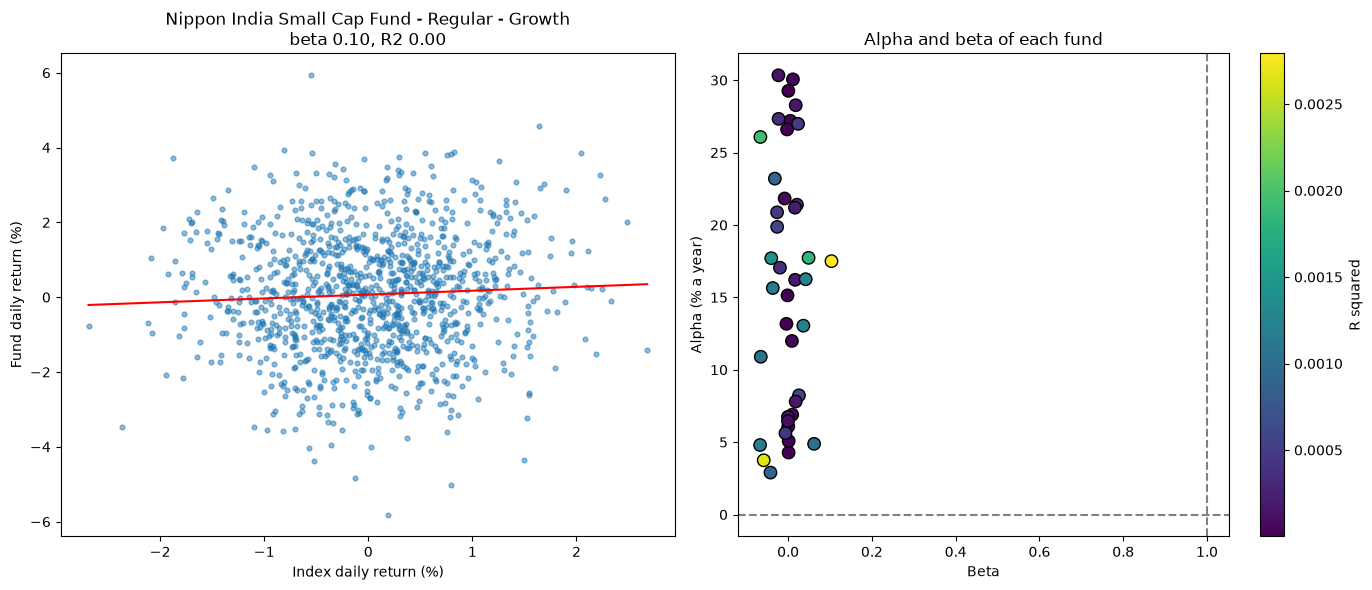

In [31]:
best_fit = ab_table.sort_values('r_squared', ascending=False).iloc[0]
sample = reg[reg['amfi_code'] == best_fit['amfi_code']]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(sample['index_return'] * 100, sample['daily_return'] * 100, s=12, alpha=0.5)
xs = np.array([sample['index_return'].min(), sample['index_return'].max()])
ys = (best_fit['alpha_ann_pct'] / 100 / TRADING_DAYS) + best_fit['beta'] * xs
axes[0].plot(xs * 100, ys * 100, color='red')
axes[0].set_xlabel('Index daily return (%)')
axes[0].set_ylabel('Fund daily return (%)')
axes[0].set_title(f'{best_fit["scheme_name"]}\nbeta {best_fit["beta"]:.2f}, R2 {best_fit["r_squared"]:.2f}')

sc = axes[1].scatter(ab_table['beta'], ab_table['alpha_ann_pct'], c=ab_table['r_squared'],
                     cmap='viridis', s=80, edgecolor='black')
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].axvline(1, color='gray', linestyle='--')
axes[1].set_xlabel('Beta')
axes[1].set_ylabel('Alpha (% a year)')
axes[1].set_title('Alpha and beta of each fund')
fig.colorbar(sc, ax=axes[1], label='R squared')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'alpha_beta_charts.png'))
plt.show()

In [32]:
nav = pd.read_sql_query("""
SELECT n.amfi_code, d.full_date, n.nav
FROM fact_nav AS n
JOIN dim_date AS d ON d.date_key = n.date_key
WHERE n.is_filled = 0
ORDER BY n.amfi_code, n.date_key
""", engine)

nav['date'] = pd.to_datetime(nav['full_date'])

print(nav.shape, '| funds:', nav['amfi_code'].nunique())

(46000, 4) | funds: 40


In [33]:
def max_drawdown(series):
    running_max = series.cummax()
    drawdown = series / running_max - 1

    trough_date = drawdown.idxmin()
    peak_value = running_max.loc[trough_date]
    peak_date = series.loc[:trough_date].idxmax()

    after = series.loc[trough_date:]
    recovered = after[after >= peak_value]
    recovery_date = recovered.index[0] if len(recovered) > 0 else pd.NaT

    return {
        'max_drawdown_pct': drawdown.min() * 100,
        'peak_date': peak_date,
        'trough_date': trough_date,
        'recovery_date': recovery_date,
        'peak_nav': peak_value,
        'trough_nav': series.loc[trough_date],
    }


# Test on the example from Part 1
test = pd.Series([100, 110, 99, 105, 120, 90, 100],
                 index=pd.date_range('2026-01-01', periods=7, freq='D'))
result = max_drawdown(test)

print(round(result['max_drawdown_pct'], 1), result['peak_date'].date(), result['trough_date'].date(), result['recovery_date'])

-25.0 2026-01-05 2026-01-06 NaT


In [34]:
def mdd_table(nav_df):
    rows = []
    for code, group in nav_df.groupby('amfi_code'):
        series = group.set_index('date')['nav'].sort_index()
        result = max_drawdown(series)
        result['amfi_code'] = code
        rows.append(result)

    out = pd.DataFrame(rows).set_index('amfi_code')
    out['fall_days'] = (out['trough_date'] - out['peak_date']).dt.days
    out['recovery_days'] = (out['recovery_date'] - out['trough_date']).dt.days
    return out


mdd_full = mdd_table(nav)
mdd_common = mdd_table(nav[nav['date'] >= COMMON_START])

index_mdd = max_drawdown(idx_close.loc[COMMON_START:])
print('Nifty 100 maximum drawdown in the common window:', round(index_mdd['max_drawdown_pct'], 1), '%',
      '| peak', index_mdd['peak_date'].date(), '| trough', index_mdd['trough_date'].date())

print(mdd_common[['max_drawdown_pct']].describe().round(2))

Nifty 100 maximum drawdown in the common window: -33.0 % | peak 2022-09-21 | trough 2024-10-17
       max_drawdown_pct
count             40.00
mean             -17.84
std               11.27
min              -52.57
25%              -21.40
50%              -16.31
75%              -11.73
max               -0.10


In [35]:
# Check A
code = int(mdd_common.index[0])
values = (nav[(nav['amfi_code'] == code) & (nav['date'] >= COMMON_START)]
          .sort_values('date')['nav'].to_numpy())

ratio = values[None, :] / values[:, None] - 1
brute = np.triu(ratio, k=1).min() * 100

print('A. Fund', code, '| brute force:', round(brute, 4), '| function:', round(mdd_common.loc[code, 'max_drawdown_pct'], 4))
print('   Same value:', np.isclose(brute, mdd_common.loc[code, 'max_drawdown_pct']))

# Check B
for name, table_ in [('common', mdd_common), ('full', mdd_full)]:
    ok = bool(((table_['max_drawdown_pct'] <= 0) & (table_['max_drawdown_pct'] > -100)).all())
    print('B.', name, 'window: all drawdowns between -100 and 0:', ok)

# Check C
check = ab_table.set_index('amfi_code')[['beta']].join(mdd_common[['max_drawdown_pct']])
print('C. Rank correlation of beta and the depth of the drawdown:',
      round(check['beta'].corr(-check['max_drawdown_pct'], method='spearman'), 2))

A. Fund 100016 | brute force: -24.7344 | function: -24.7344
   Same value: True
B. common window: all drawdowns between -100 and 0: True
B. full window: all drawdowns between -100 and 0: True
C. Rank correlation of beta and the depth of the drawdown: -0.03


In [36]:
dd = mdd_common.reset_index().merge(funds, on='amfi_code', how='left')
dd['trough_month'] = dd['trough_date'].dt.to_period('M')

cols = ['scheme_name', 'category', 'max_drawdown_pct', 'peak_date', 'trough_date',
        'recovery_date', 'fall_days', 'recovery_days']

print('Worst 10 drawdowns, common window')
print(dd.sort_values('max_drawdown_pct').head(10)[cols].round(2).to_string(index=False))
print()
print('Months with the most troughs:')
print(dd['trough_month'].value_counts().head(5))
print()
print('Funds that have not recovered:', int(dd['recovery_date'].isnull().sum()))

worst = dd.sort_values('max_drawdown_pct').iloc[0]
print()
print('Worst drawdown of all funds:', worst['scheme_name'])
print('  ', round(worst['max_drawdown_pct'], 2), '% from', worst['peak_date'].date(), 'to', worst['trough_date'].date())

Worst 10 drawdowns, common window
                                   scheme_name category  max_drawdown_pct  peak_date trough_date recovery_date  fall_days  recovery_days
     SBI Small Cap Fund - Direct Plan - Growth   Equity            -52.57 2023-01-17  2025-10-28           NaT       1015            NaN
        Axis Small Cap Fund - Regular - Growth   Equity            -51.68 2025-05-22  2026-05-11           NaT        354            NaN
        ABSL Small Cap Fund - Regular - Growth   Equity            -35.45 2024-11-21  2026-05-11           NaT        536            NaN
         DSP Small Cap Fund - Regular - Growth   Equity            -31.17 2024-05-03  2025-01-03    2025-06-13        245          161.0
    SBI Small Cap Fund - Regular Plan - Growth   Equity            -28.71 2024-08-28  2025-05-14    2025-09-29        259          138.0
           UTI Mid Cap Fund - Regular - Growth   Equity            -28.00 2025-01-07  2026-04-27           NaT        475            NaN
     HD

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_25444\4207019029.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(dd.sort_values('max_drawdown_pct').head(10)[cols].round(2).to_string(index=False))


In [37]:
src_dd = pd.read_sql_query(
    'SELECT amfi_code, max_drawdown_pct AS source_pct FROM fact_performance', engine)

cmp_dd = mdd_full.reset_index()[['amfi_code', 'max_drawdown_pct']].merge(src_dd, on='amfi_code', how='left')
cmp_dd_common = mdd_common.reset_index()[['amfi_code', 'max_drawdown_pct']].merge(src_dd, on='amfi_code', how='left')

print('Source: negative values:', int((src_dd['source_pct'] < 0).sum()), '| positive values:', int((src_dd['source_pct'] > 0).sum()))

for name, table_ in [('full history', cmp_dd), ('common window', cmp_dd_common)]:
    size_diff = (table_['max_drawdown_pct'].abs() - table_['source_pct'].abs()).abs().mean()
    rho = table_['max_drawdown_pct'].corr(table_['source_pct'], method='spearman')
    print(f'{name}: mean difference in size {size_diff:.2f} | rank correlation (signed) {rho:.2f}')

Source: negative values: 40 | positive values: 0
full history: mean difference in size 9.16 | rank correlation (signed) 0.23
common window: mean difference in size 9.17 | rank correlation (signed) 0.23


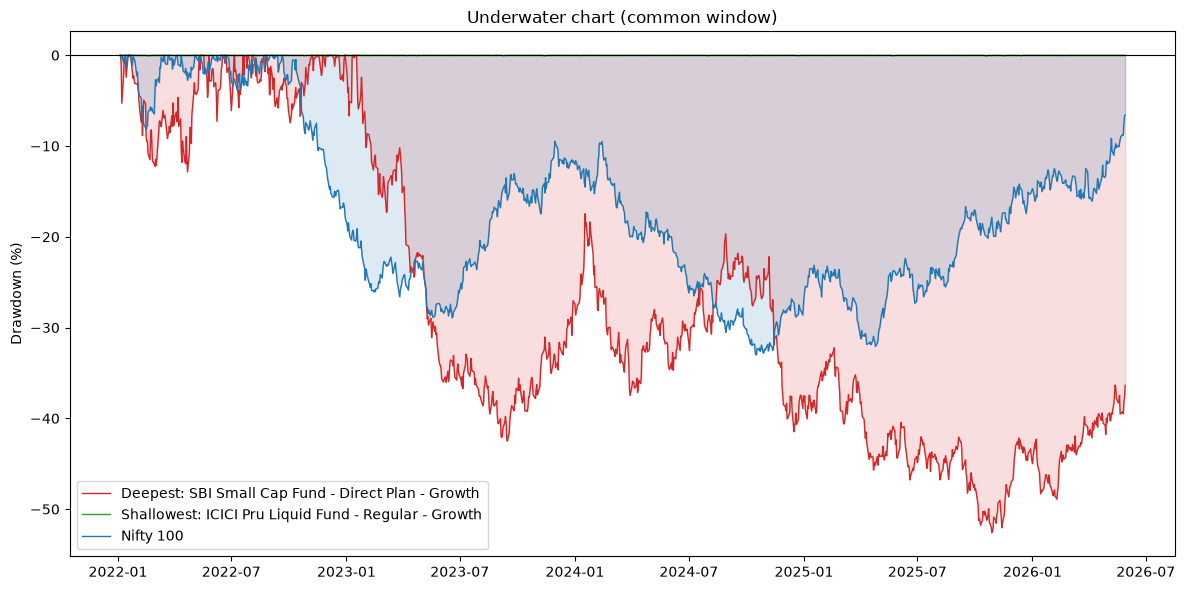

In [38]:
def drawdown_series(series):
    return (series / series.cummax() - 1) * 100


deep_code = int(mdd_common['max_drawdown_pct'].idxmin())
shallow_code = int(mdd_common['max_drawdown_pct'].idxmax())

def fund_series(code):
    group = nav[(nav['amfi_code'] == code) & (nav['date'] >= COMMON_START)]
    return group.set_index('date')['nav'].sort_index()

names = funds.set_index('amfi_code')['scheme_name']

plt.figure(figsize=(12, 6))
for series, label, color in [
    (fund_series(deep_code), 'Deepest: ' + str(names.get(deep_code)), 'tab:red'),
    (fund_series(shallow_code), 'Shallowest: ' + str(names.get(shallow_code)), 'tab:green'),
    (idx_close.loc[COMMON_START:], 'Nifty 100', 'tab:blue'),
]:
    dd_series = drawdown_series(series)
    plt.plot(dd_series.index, dd_series.values, label=label, color=color, linewidth=1)
    plt.fill_between(dd_series.index, dd_series.values, 0, color=color, alpha=0.15)

plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('Drawdown (%)')
plt.title('Underwater chart (common window)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'drawdown_underwater.png'))
plt.show()

In [39]:
ab_cols = ['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'is_idcw', 'days',
           'beta', 'beta_stderr', 'alpha_ann_pct', 'alpha_t', 'alpha_jensen_ann_pct',
           'r_squared', 'rank_alpha', 'weak_fit', 'alpha_significant']
ab_table.sort_values('rank_alpha')[ab_cols].round(4).to_csv(
    os.path.join(PROCESSED_DIR, 'fund_alpha_beta.csv'), index=False)

dd_out = dd.merge(mdd_full[['max_drawdown_pct', 'peak_date', 'trough_date', 'recovery_date']].add_suffix('_full'),
                  left_on='amfi_code', right_index=True, how='left')
dd_out.sort_values('max_drawdown_pct').drop(columns=['trough_month']).round(4).to_csv(
    os.path.join(PROCESSED_DIR, 'fund_max_drawdown.csv'), index=False)

lines = [
    '# Alpha, beta, and maximum drawdown summary',
    '',
    f'- Index: {NIFTY_NAME}. Regression window: {WINDOW_START.date()} to {WINDOW_END.date()} ({years:.2f} years). Funds: {len(capm)}.',
    '- Regression: fund daily return on index daily return, scipy.stats.linregress. Beta = slope. Alpha = intercept x 252, in percent.',
    '- Fund and index returns cover the same dates (index close looked up on each start and end date).',
    f'- Funds with a weak fit (R2 below 0.5): {int(ab_table["weak_fit"].sum())}. Funds with a significant alpha (t above 2 in size): {int(ab_table["alpha_significant"].sum())}.',
    f'- Beta: median {ab_table["beta"].median():.2f}, min {ab_table["beta"].min():.2f}, max {ab_table["beta"].max():.2f}.',
    f'- Alpha (plain) median {ab_table["alpha_ann_pct"].median():.2f}% a year. Alpha (Jensen, risk-free rate removed) median {ab_table["alpha_jensen_ann_pct"].median():.2f}% a year.',
    '- Maximum drawdown = min(NAV / running max - 1), on real NAV days.',
    f'- Common-window drawdown: median {mdd_common["max_drawdown_pct"].median():.1f}%, worst {mdd_common["max_drawdown_pct"].min():.1f}% ({worst["scheme_name"]}, {worst["peak_date"].date()} to {worst["trough_date"].date()}).',
    f'- {NIFTY_NAME} drawdown in the same window: {index_mdd["max_drawdown_pct"]:.1f}% ({index_mdd["peak_date"].date()} to {index_mdd["trough_date"].date()}).',
    f'- Funds that have not recovered to their peak: {int(dd["recovery_date"].isnull().sum())}.',
    '- Checks passed: index regressed on itself gives slope 1, one fund recomputed by hand, brute force drawdown for one fund, drawdowns between -100 and 0.',
    '',
    '## Assumptions to confirm',
    '- All funds are compared with the Nifty 100. Small cap, debt, and liquid funds fit it poorly (see weak_fit).',
    '- The index file may be a price index. Then alpha is a little too high (dividends are missing).',
    '- The rule for repeated index dates: keep the last row.',
    '- Alpha uses plain returns, as in the task. Jensen alpha is shown for comparison.',
    '- Drawdown uses real NAV days only. The full-history values depend on how long each fund has existed.',
]

summary_text = '\n'.join(lines)

with open(os.path.join(REPORTS_DIR, 'alpha_beta_drawdown_summary.md'), 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(summary_text)

# Alpha, beta, and maximum drawdown summary

- Index: NIFTY100. Regression window: 2022-01-04 to 2026-05-29 (4.40 years). Funds: 40.
- Regression: fund daily return on index daily return, scipy.stats.linregress. Beta = slope. Alpha = intercept x 252, in percent.
- Fund and index returns cover the same dates (index close looked up on each start and end date).
- Funds with a weak fit (R2 below 0.5): 40. Funds with a significant alpha (t above 2 in size): 29.
- Beta: median -0.00, min -0.07, max 0.10.
- Alpha (plain) median 16.23% a year. Alpha (Jensen, risk-free rate removed) median 9.92% a year.
- Maximum drawdown = min(NAV / running max - 1), on real NAV days.
- Common-window drawdown: median -16.3%, worst -52.6% (SBI Small Cap Fund - Direct Plan - Growth, 2023-01-17 to 2025-10-28).
- NIFTY100 drawdown in the same window: -33.0% (2022-09-21 to 2024-10-17).
- Funds that have not recovered to their peak: 4.
- Checks passed: index regressed on itself gives slope 1, one fund recomputed by 

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_25444\3590687523.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  dd_out.sort_values('max_drawdown_pct').drop(columns=['trough_month']).round(4).to_csv(
